## Workflow hiện tại: cascade

Mở [notebook wav2vec2 + Qwen3-0.6B](mdd_cascade_training_comparison.ipynb) để xem dữ liệu, train và so sánh trên split chung sạch. Notebook bên dưới giữ lại công cụ duyệt template cũ; workflow L2-Arctic-plus mới không yêu cầu bạn duyệt 300 mẫu đó.

# Duyệt dữ liệu hướng dẫn phát âm và chuẩn bị train Qwen3

Code đã cập nhật đến `cef406b` (21/10/2026). Phần mới train adapter QLoRA cho
**Qwen3-0.6B**, sinh hướng dẫn tiếng Việt từ assessment MDD; model này không nhận audio
và không cập nhật wav2vec2. Những cell train phía cuối mặc định tắt.

**300 bản nháp chưa được duyệt** được tạo bằng template offline từ kết quả validation
MDD đã lưu. Không có giáo viên hay LLM xác nhận nội dung template.
Đọc câu, nghe audio, đối chiếu nhãn thủ công rồi sửa assessment/hướng dẫn nếu cần.
Người duyệt phải bổ sung cách luyện cụ thể trước khi chấp nhận. Không coi cảnh báo MDD
là lỗi phát âm chắc chắn. Mở notebook bằng kernel **MDD (.venv)** và Run All để mở trình duyệt mẫu.

In [1]:
from pathlib import Path
from copy import deepcopy
from collections import Counter
import json, os, sys, subprocess
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Audio, Markdown, clear_output

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/train_feedback_model.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from scripts.prepare_feedback_data import read_rows, split_rows, digest
from scripts.review_feedback_drafts import approve_one
DRAFTS = ROOT / 'data/feedback/drafts-20261021-cef406b.jsonl'
REVIEWED = ROOT / "data/feedback/reviewed.jsonl"
DATASET = ROOT / "data/processed/feedback-v1"
PYTHON = ROOT / ".venv/Scripts/python.exe"
drafts = read_rows(DRAFTS, reviewed=False)
manifest = json.loads(DRAFTS.with_suffix(".manifest.json").read_text(encoding="utf-8"))
assert digest(DRAFTS) == manifest["drafts_sha256"]
assert all(row["review"]["approved"] is False for row in drafts)
print("Bản nháp:", DRAFTS)
print("Đích lưu khi bấm duyệt:", REVIEWED)

Bản nháp: D:\NCC\MDD\data\feedback\drafts-20261021-cef406b.jsonl
Đích lưu khi bấm duyệt: D:\NCC\MDD\data\feedback\reviewed.jsonl


## 1. Tình trạng cài đặt và kiểm tra GPU thật

Checkpoint Qwen công khai được ghim revision, xác minh SHA-256. Torch CUDA đang có được giữ nguyên.
Kết quả một optimizer update dưới đây là **kiểm tra kỹ thuật**, dùng bản nháp chưa duyệt;
adapter thử nghiệm nằm trong `runs/local-checks/` và không bật trong demo. Lượt Trainer
dùng lại mẫu kỹ thuật để kiểm tra validation/save; không dùng loss này để kết luận chất lượng model.
Giữ nguyên prompt, mask loss của prompt và token câu trả lời. Tối ưu chỉ bỏ projection
từ vựng ở vị trí không đóng góp loss; đã kiểm tra loss/gradient tương đương bằng model nhỏ.
[API logits_to_keep của Qwen3](https://huggingface.co/docs/transformers/v4.57.1/en/model_doc/qwen3).

In [2]:
probe_dirs = ["feedback-qlora-20261021-cef406b", "feedback-qlora-20261021-efficient", "feedback-qlora-20261021-trainer"]
checks = []
for label in probe_dirs:
    path = ROOT / "runs/local-checks" / label / "report.json"
    if path.is_file():
        report = json.loads(path.read_text(encoding="utf-8"))
        checks.append({"Kiểm tra":label, "Trạng thái":report["status"],
            "Bước cập nhật":report["optimizer_updates"], "Token đã kiểm tra":report.get("tested_sequence_length"),
            "Loss":report.get("loss"), "Peak allocated GiB":report.get("peak_allocated_bytes",0)/2**30,
            "Peak reserved GiB":report.get("peak_reserved_bytes",0)/2**30,
            "Weights nền giữ nguyên":report.get("base_weight_file_unchanged")})
display(pd.DataFrame(checks).set_index("Kiểm tra").round(4))
print("Recipe chính:", json.loads((ROOT / "configs/feedback_qlora_rtx3050.json").read_text(encoding="utf-8")))

,Trạng thái,Bước cập nhật,Token đã kiểm tra,Loss,Peak allocated GiB,Peak reserved GiB,Weights nền giữ nguyên
Kiểm tra,,,,,,,
feedback-qlora-20261021-cef406b,passed,1,3072,1.1555,6.6623,7.6309,True
feedback-qlora-20261021-efficient,passed,1,3072,1.1555,2.1022,2.3047,True
feedback-qlora-20261021-trainer,passed,1,3072,1.1555,2.1156,2.4180,True


Recipe chính: {'model_path': 'models/pretrained/Qwen3-0.6B', 'dataset_dir': 'data/processed/feedback-v1', 'output_dir': 'runs/feedback-qwen3-06b-v1', 'max_length': 3072, 'epochs': 3, 'learning_rate': 0.0001, 'gradient_accumulation_steps': 8, 'lora_rank': 8, 'lora_alpha': 16, 'lora_dropout': 0.05, 'target_modules': ['q_proj', 'v_proj'], 'min_train_examples': 100, 'min_validation_examples': 20, 'seed': 42}


## 2. Nguồn và phân bố bản nháp

Dùng dự đoán validation đã lưu của A/B, kèm audio và nhãn thủ công L2-ARCTIC để hỗ trợ
người duyệt. Nhãn thủ công chỉ nằm trong `review_context`, không đưa vào prompt huấn luyện.
Không dùng dự đoán test, không cắt nhãn để vừa context, không gọi LLM/ai33 để tạo bộ này.
Split dưới đây là **dự kiến nếu mọi bản nháp được duyệt**, chưa tạo dataset train.

Số mẫu: 300 · nhóm câu: 190 · đã duyệt trong file nháp: 0
Split dự kiến: {'train': 242, 'validation': 29, 'test': 29}
Ứng viên không đưa vào: {'unavailable_word_mapping': 9}


,samples,avg_errors,max_tokens
model,,,
run:windows-notebook-seed42-A:best,208,6.701923,2212
run:windows-notebook-seed42-B-fold1:best,92,5.456522,2308


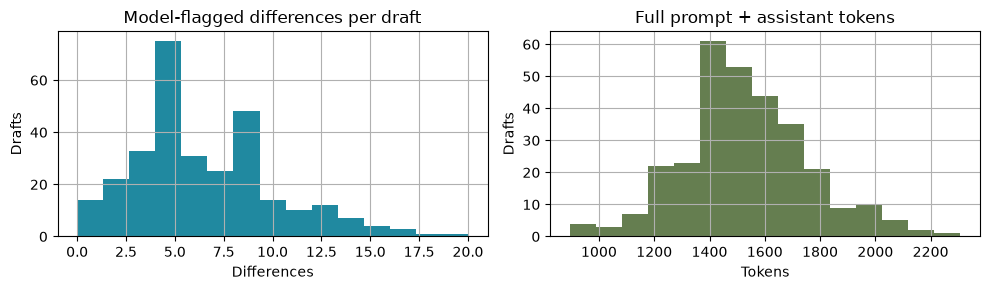

In [3]:
frame = pd.DataFrame([{"id":r["assessment"]["utterance_id"], "model":r["assessment"]["model_id"],
    "speaker":r["provenance"]["speaker_id"], "language":r["provenance"].get("native_language"),
    "errors":len(r["assessment"]["errors"]), "tokens":r["provenance"]["training_tokens"]} for r in drafts])
print("Số mẫu:",len(drafts), "· nhóm câu:",manifest["unique_prompt_groups"], "· đã duyệt trong file nháp: 0")
print("Split dự kiến:", manifest["prospective_split_if_every_draft_is_approved"])
print("Ứng viên không đưa vào:", manifest["candidate_rejections"])
display(frame.groupby("model").agg(samples=("id","size"), avg_errors=("errors","mean"), max_tokens=("tokens","max")))
fig, axes = plt.subplots(1,2,figsize=(10,3))
frame["errors"].hist(ax=axes[0],bins=15,color="#2089a0")
frame["tokens"].hist(ax=axes[1],bins=15,color="#657e50")
axes[0].set(title="Model-flagged differences per draft",xlabel="Differences",ylabel="Drafts")
axes[1].set(title="Full prompt + assistant tokens",xlabel="Tokens",ylabel="Drafts")
fig.tight_layout(); display(fig); plt.close(fig)

## 3. Nghe và xem một mẫu trước khi chỉnh sửa

Ô **Assessment** là thông tin đưa vào LLM: có thể sửa cảnh báo sai khi đã nghe và kiểm tra nhãn.
Ô **Feedback** là đích LLM cần học: tiếng Việt, tối đa 3 tips, đúng `error_id`, đúng từ và âm;
có hai `tts_segments` cho câu tiếng Anh và hướng dẫn tiếng Việt. IPA không biết được giữ `null`.
Mỗi lần lưu phải nhập tên người thực sự duyệt. Chạy cell không tự chấp nhận mẫu nào.

In [4]:
first = drafts[0]
display(Markdown("**"+first["assessment"]["reference_text"]+"**"))
display(Audio(filename=str(ROOT / first["provenance"]["audio_path"]), embed=True))
display(pd.DataFrame(first["assessment"]["errors"]))
print("Âm chuẩn:"," ".join(first["review_context"]["canonical_phones"]))
print("Model nhận:"," ".join(first["review_context"]["predicted_phones"]))
print("Nhãn người phiên âm:"," ".join(first["review_context"]["human_perceived_phones"]))
print("Việc cần kiểm tra:",first["review_context"]["needs_review"])

**Without a doubt some of them have dinner engagements**

,id,word_index,type,expected_phone,observed_phone,expected_ipa,observed_ipa,start_sec,end_sec,confidence
0,e1,0,substitution,DH,D,ð,d,None,None,None
1,e2,0,deletion,T,None,t,None,None,None,None
2,e3,7,substitution,ER,AH,None,None,None,None,None
3,e4,8,substitution,EH,IH,ɛ,ɪ,None,None,None


Âm chuẩn: W IH DH AW T AH D AW T S AH M AH V DH AH M HH AE V D IH N ER EH N G EY JH M AH N T S
Model nhận: W IH D AW AH D AW T S AH M AH V DH AH M HH AE V D IH N AH IH N G EY JH M AH N T S
Nhãn người phiên âm: W IH D AW AH D AW T S AH M AH V DH AH M HH EH V D IH N AH EH N G EY SH M AH N T S
Việc cần kiểm tra: ['Nghe audio và đối chiếu nhãn thủ công; cảnh báo model có thể sai.', 'Sửa assessment nếu cần; giữ error_id, từ, loại lỗi và âm liên kết đúng.', 'Bổ sung hướng dẫn môi/lưỡi và bài luyện cụ thể; template hiện chỉ gợi ý chung.', 'Sửa đoạn giọng đọc tiếng Việt để khớp hướng dẫn đã duyệt.']


## 4. Công cụ duyệt từng mẫu

Chọn số mẫu → nghe audio → sửa hai ô JSON → nhập tên và ghi chú → tick xác nhận →
**Duyệt và lưu**. Nút chỉ chấp nhận đúng schema, liên kết lỗi và tối đa 3.072 token.
Mẫu được lưu riêng vào `reviewed.jsonl`; file nháp gốc giữ nguyên.
“Mẫu tiếp” chỉ chuyển mẫu, không duyệt. Nếu sửa sau khi đã duyệt, lưu lại sẽ cập nhật đúng ID đó.

In [5]:
from transformers import AutoTokenizer
review_tokenizer = AutoTokenizer.from_pretrained(str(ROOT / "models/pretrained/Qwen3-0.6B"), local_files_only=True, trust_remote_code=False)
picker = widgets.BoundedIntText(value=0,min=0,max=len(drafts)-1,description="Mẫu số:")
reviewer = widgets.Text(value="",description="Người duyệt:",layout=widgets.Layout(width="100%"))
notes = widgets.Textarea(value="",description="Ghi chú:",layout=widgets.Layout(width="100%",height="65px"))
assessment_editor = widgets.Textarea(description="Assessment",layout=widgets.Layout(width="100%",height="260px"))
feedback_editor = widgets.Textarea(description="Feedback",layout=widgets.Layout(width="100%",height="310px"))
confirmation = widgets.Checkbox(value=False,description="Tôi đã nghe, kiểm tra âm và sửa nội dung hướng dẫn.")
approve_button = widgets.Button(description="Duyệt và lưu",button_style="success")
next_button = widgets.Button(description="Mẫu tiếp →")
detail = widgets.Output()
messages = widgets.Output()
def load_item(change=None):
    row = drafts[picker.value]
    assessment_editor.value=json.dumps(row["assessment"],ensure_ascii=False,indent=2)
    feedback_editor.value=json.dumps(row["feedback"],ensure_ascii=False,indent=2)
    confirmation.value=False; notes.value=""
    with detail:
        clear_output(wait=True)
        print(f"Mẫu {picker.value+1}/{len(drafts)} · {row['assessment']['utterance_id']}")
        print(row["assessment"]["reference_text"])
        display(Audio(filename=str(ROOT / row["provenance"]["audio_path"]),embed=True))
        display(pd.DataFrame(row["assessment"]["errors"]))
        print("Nhãn người phiên âm:"," ".join(row["review_context"]["human_perceived_phones"]))
        print("Nhãn lỗi thủ công:",row["review_context"]["human_annotation_events"])
def save_item(button):
    with messages:
        clear_output(wait=True)
        if not confirmation.value:
            print("Chưa lưu: cần nghe và kiểm tra mẫu rồi tick xác nhận."); return
        try:
            approve_one(drafts[picker.value],json.loads(assessment_editor.value),json.loads(feedback_editor.value),
                        reviewer.value,REVIEWED,tokenizer=review_tokenizer,notes=notes.value)
            print("Đã lưu mẫu đã duyệt:",drafts[picker.value]["assessment"]["utterance_id"])
            print("Tổng số mẫu đã duyệt:",len(read_rows(REVIEWED)))
            confirmation.value=False
        except Exception as error: print("Chưa lưu:",str(error))
def next_item(button): picker.value=min(len(drafts)-1,picker.value+1)
picker.observe(load_item,names="value")
approve_button.on_click(save_item); next_button.on_click(next_item)
load_item()
display(widgets.VBox([picker,detail,assessment_editor,feedback_editor,reviewer,notes,confirmation,
                      widgets.HBox([approve_button,next_button]),messages]))

## 5. Kiểm tra số mẫu đã duyệt và đóng băng split

In [6]:
approved = read_rows(REVIEWED) if REVIEWED.is_file() else []
proposed = split_rows(approved,42) if len({r["group_id"] for r in approved})>=3 else {}
counts={name:len(rows) for name,rows in proposed.items()}
ready=counts.get("train",0)>=100 and counts.get("validation",0)>=20
print("Đã duyệt:",len(approved),"· phân bố dự kiến:",counts,"· đủ điều kiện train:",ready)
RUN_PREPARE=False
if RUN_PREPARE:
    if not ready: raise ValueError("Cần >=100 train, >=20 validation và các nhóm độc lập; tiếp tục duyệt.")
    subprocess.run([str(PYTHON),"-X","utf8","scripts/prepare_feedback_data.py","prepare",str(REVIEWED),"--output",str(DATASET)],cwd=ROOT,check=True)
print("Prepare:",subprocess.list2cmdline([str(PYTHON),"-X","utf8","scripts/prepare_feedback_data.py","prepare",str(REVIEWED),"--output",str(DATASET)]))

Đã duyệt: 0 · phân bố dự kiến: {} · đủ điều kiện train: False
Prepare: D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/prepare_feedback_data.py prepare D:\NCC\MDD\data\feedback\reviewed.jsonl --output D:\NCC\MDD\data\processed\feedback-v1


## 6. Lệnh train chính sau khi có dữ liệu đã duyệt

Giữ recipe 3 epochs, QLoRA NF4 rank 8, `q_proj`/`v_proj`, accumulation 8.
Chọn bằng validation loss; test để đánh giá sau khi khóa recipe.
Dataset và output có sẵn sẽ được bảo vệ khỏi ghi đè. Không dùng adapter kiểm tra kỹ thuật trong demo.

In [7]:
check_command=[str(PYTHON),"-X","utf8","scripts/train_feedback_model.py","--check-data-only"]
train_command=[str(PYTHON),"-X","utf8","scripts/train_feedback_model.py","--config","configs/feedback_qlora_rtx3050.json"]
print("Kiểm tra:",subprocess.list2cmdline(check_command))
print("Train:",subprocess.list2cmdline(train_command))
RUN_TRAIN=False
if RUN_TRAIN:
    subprocess.run(check_command,cwd=ROOT,check=True)
    subprocess.run(train_command,cwd=ROOT,check=True)
else: print("Train chính chưa chạy: chờ duyệt dữ liệu. Kiểm tra GPU một bước đã lưu riêng.")

Kiểm tra: D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/train_feedback_model.py --check-data-only
Train: D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/train_feedback_model.py --config configs/feedback_qlora_rtx3050.json
Train chính chưa chạy: chờ duyệt dữ liệu. Kiểm tra GPU một bước đã lưu riêng.
